# Experiment 6 — Probabilistic Forecast Evaluation

Đánh giá các intervals **negative binomial gốc**: calibration, width và WIS theo horizon, lịch sử và điều kiện dịch. Bộ paper **N=18.387, k=5, m=4.422**, GAM, bỏ bridge; **50 bang × 112 origins × 4 horizons**.

**UQ `matured`, `nonconstant_v2`**: MLE chỉ dùng pairs đã phát trước origin và target_end_date ≤ origin. Frozen warmup và final revisions vẫn là giới hạn hồi cứu; không gọi toàn bộ backtest là real-time/causal. Notebook kiểm tra nguồn full mới, source/input/artifact hashes, 22.400 NB sizes và zero future targets trước khi hiển thị. Coverage chính inclusive `L ≤ y ≤ U`; đồng thời giữ source convention `L < y ≤ U`.

Chạy runner trước nếu chưa có outputs: `.venv/bin/python experiments/probabilistic/experiment_6.py`.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
while not (ROOT / "experiments/probabilistic/experiment_6.py").exists():
    if ROOT == ROOT.parent:
        raise RuntimeError("Không tìm thấy project root")
    ROOT = ROOT.parent
OUT = ROOT / "outputs/experiment_6_nonconstant_v2_matured"
import sys
sys.path.insert(0, str(ROOT))
from experiments.probabilistic.experiment_6 import validate_outputs
summary = validate_outputs(OUT)
metrics = pd.read_csv(OUT / "metrics.csv")
calibration = pd.read_csv(OUT / "calibration.csv")
correlations = pd.read_csv(OUT / "width_correlations.csv")
instances = pd.read_csv(OUT / "instances.csv.gz")
print(f"{summary['states']} states; {summary['origins']} origins; {summary['forecasts']:,} targets")
print(f"WIS={summary['WIS']:,.2f}; MAE={summary['MAE']:,.2f}; 95% coverage={summary['coverage95']:.2%}; MPIW={summary['MPIW95']:,.2f}")
print("Empty groups:", summary["empty_groups"])


50 states; 112 origins; 22,400 targets
WIS=4,747.38; MAE=7,384.66; 95% coverage=87.22%; MPIW=39,436.28
Empty groups: ['history_stage: early <=26 weeks', 'dispersion_method: initial']


## Coverage, sharpness và forecast horizon

Coverage 95% lý tưởng gần 95%; gap âm là undercoverage trên mẫu này. MPIW nhỏ chỉ tốt khi coverage vẫn đủ. WIS dùng **bảy quantiles** của source, giữ nguyên để đối chiếu; MPIW có cả đơn vị ca và chuẩn hóa bằng mean last4 ở origin. CI bootstrap nguyên bang, không coi các targets chồng lấn độc lập.

,dimension,group,n,MAE,WIS,normalized_WIS
0,overall,all,22400,7384.661652,4747.378356,0.412369
1,horizon,1,5600,4173.930357,2628.442657,0.185422
2,horizon,2,5600,6273.882946,4008.564262,0.310022
3,horizon,3,5600,8808.290536,5655.202296,0.482047
4,horizon,4,5600,10282.542768,6697.304209,0.671985


,dimension,group,n,coverage,coverage_lo,coverage_hi,source_coverage,boundary_additions,MPIW,normalized_MPIW
1,overall,all,22400,0.872188,0.860285,0.883842,0.871696,11,39436.280512,2.662723
12,horizon,1,5600,0.915893,0.901871,0.927951,0.915893,0,23848.235134,1.505961
23,horizon,2,5600,0.899643,0.886504,0.911973,0.898929,4,38115.755353,2.450087
34,horizon,3,5600,0.858036,0.844277,0.871080,0.857679,2,45993.747121,3.099638
45,horizon,4,5600,0.815179,0.803121,0.827415,0.814286,5,49787.384442,3.595204


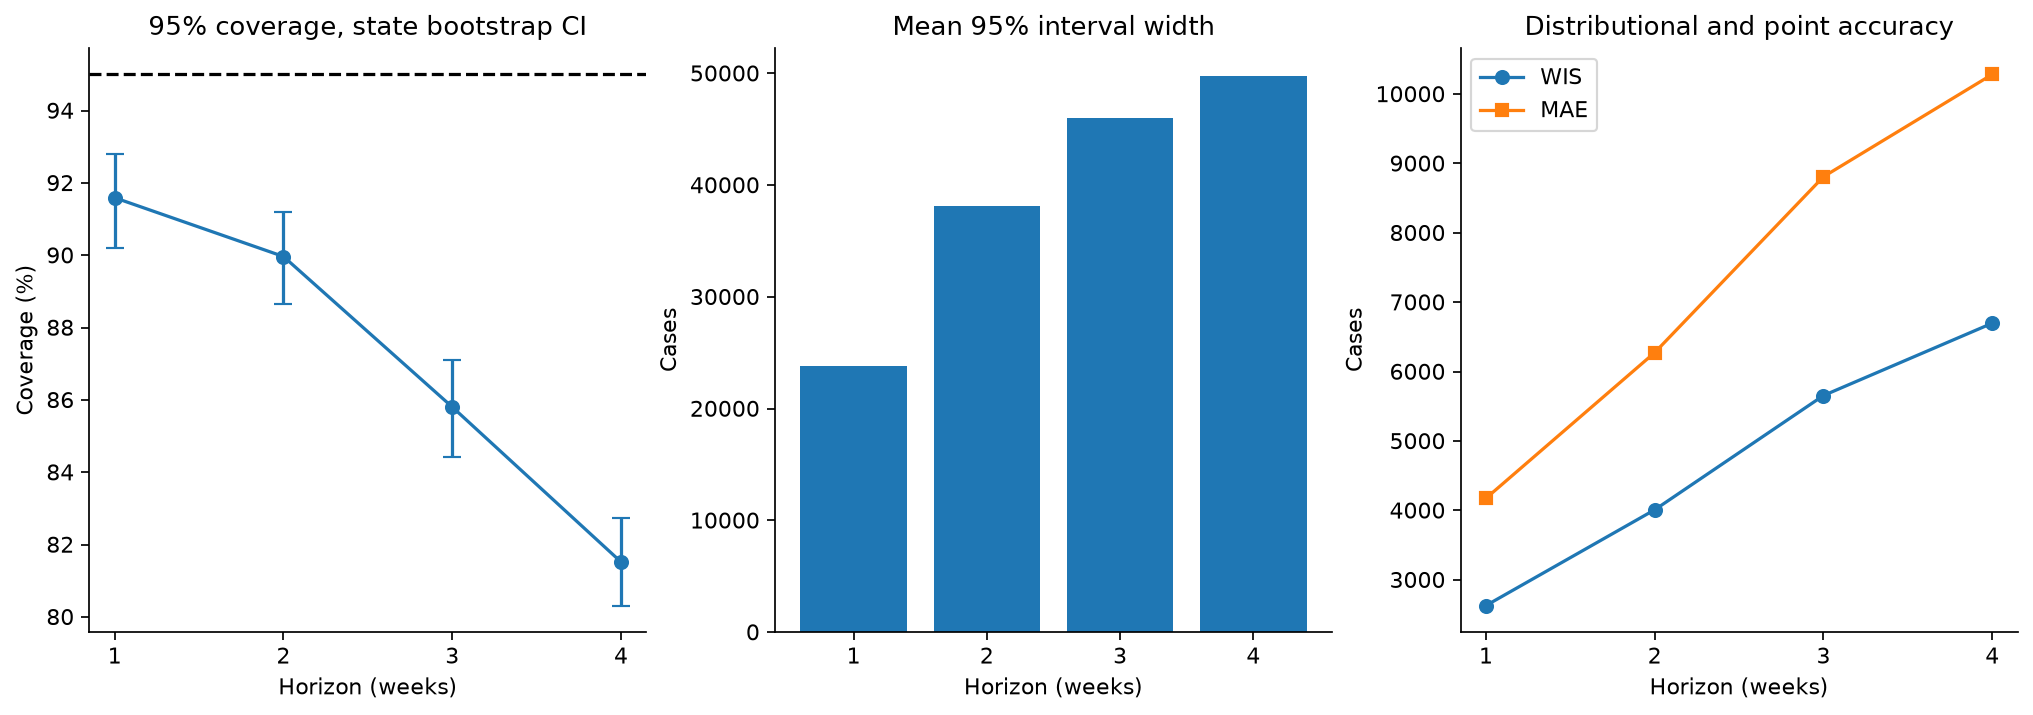

In [2]:
display(metrics.loc[metrics.dimension.isin(["overall", "horizon"]),
    ["dimension", "group", "n", "MAE", "WIS", "normalized_WIS"]])
display(calibration.loc[calibration.dimension.isin(["overall", "horizon"]) & calibration.level.eq(.95),
    ["dimension", "group", "n", "coverage", "coverage_lo", "coverage_hi", "source_coverage", "boundary_additions", "MPIW", "normalized_MPIW"]])
display(Image(filename=str(OUT / "figures/horizon_metrics.png")))


,level,coverage,calibration_gap,lower_miss_rate,upper_miss_rate,MPIW
10,0.10,0.125312,0.025312,0.381563,0.493125,2286.972978
9,0.20,0.245491,0.045491,0.320000,0.434509,4626.444777
8,0.30,0.361429,0.061429,0.260625,0.377946,7048.556386
7,0.40,0.466741,0.066741,0.208214,0.325045,9641.266812
6,0.50,0.559732,0.059732,0.162232,0.278036,12445.598583
5,0.60,0.639196,0.039196,0.124196,0.236607,15647.508705
4,0.70,0.712321,0.012321,0.089732,0.197946,19473.133797
3,0.80,0.778393,-0.021607,0.059777,0.161830,24447.841616
2,0.90,0.839732,-0.060268,0.034554,0.125714,32256.295223
1,0.95,0.872188,-0.077812,0.024464,0.103348,39436.280512


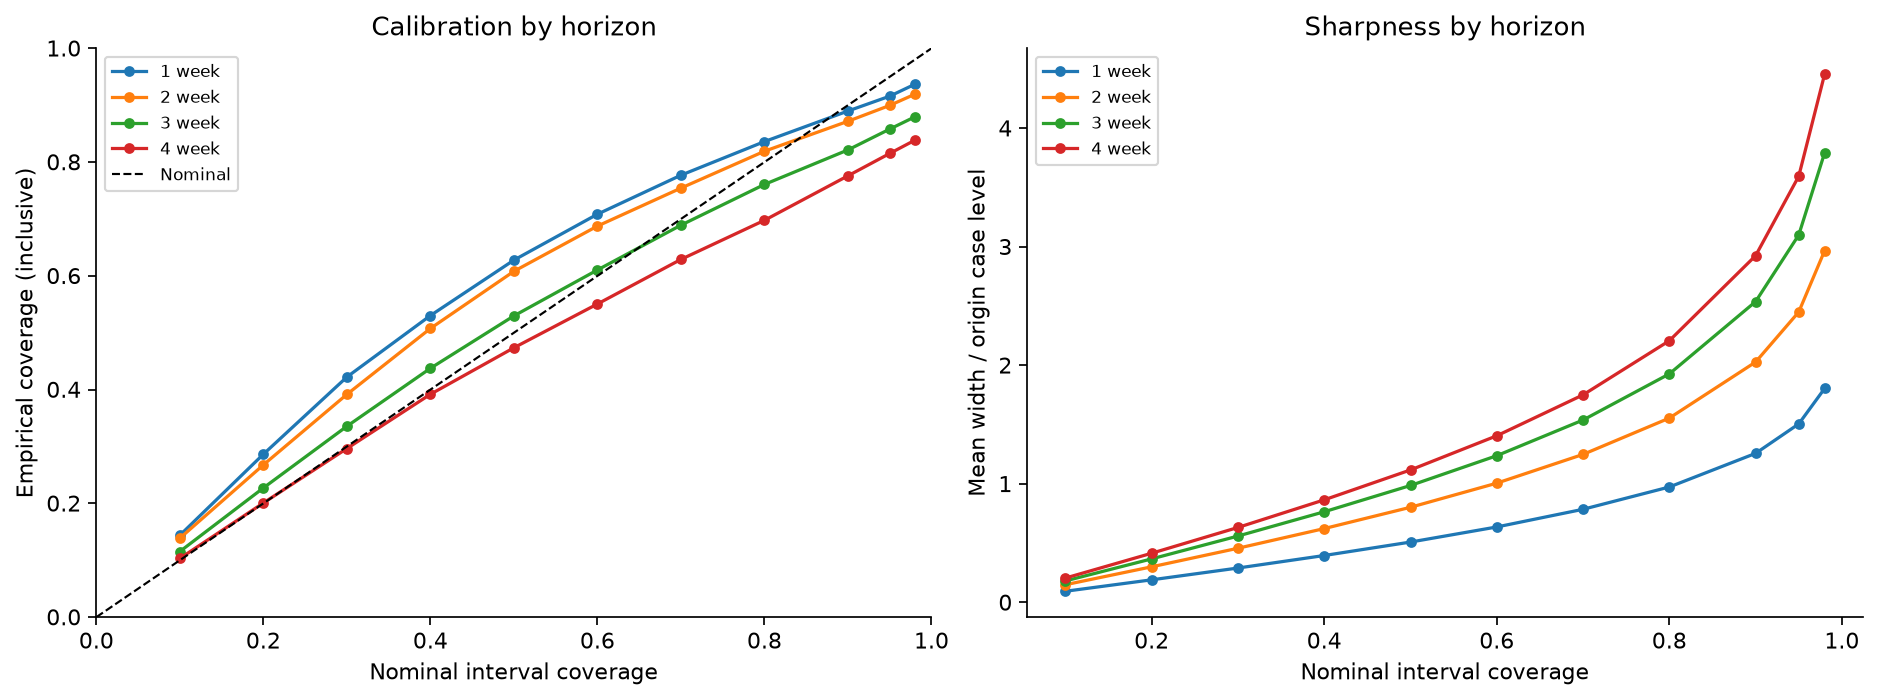

In [3]:
display(calibration.loc[calibration.dimension.eq("overall"),
    ["level", "coverage", "calibration_gap", "lower_miss_rate", "upper_miss_rate", "MPIW"]].sort_values("level"))
display(Image(filename=str(OUT / "figures/reliability_width.png")))


## Phân tầng theo điều kiện dịch và lịch sử

Phase dùng hai tuần gần nhất so với hai tuần trước, ngưỡng ±10%; level dùng mean last4, ngưỡng 1.000/10.000 ca. Features chỉ lấy từ vintage input của origin. History có 30–141 tuần: **không có early ≤26 tuần**; các bins cố định là 27–52, 53–104, ≥105 tuần. Khác biệt history không tách được hoàn toàn khỏi thời điểm dịch.

,dimension,group,n,states,coverage,coverage_lo,coverage_hi,calibration_gap,MPIW,normalized_MPIW
56,history_band,105+ weeks,7400,50,0.835135,0.805128,0.860811,-0.114865,35603.186111,2.433465
67,history_band,27–52 weeks,4600,50,0.956522,0.942174,0.969141,0.006522,42936.953000,3.011597
78,history_band,53–104 weeks,10400,50,0.861250,0.848462,0.873942,-0.088750,40615.300236,2.671539
100,phase,declining,9128,50,0.806420,0.789012,0.824414,-0.143580,17560.196776,1.248785
111,phase,rising,9064,50,0.912290,0.899534,0.923817,-0.037710,63555.339762,4.262698
122,phase,stable,4208,50,0.928470,0.913780,0.941965,-0.021530,34937.644415,2.283504
133,case_level,high,8680,48,0.876959,0.852854,0.894048,-0.073041,85563.312742,2.521324
144,case_level,low,2188,29,0.782450,0.730904,0.818653,-0.167550,1657.651028,3.030275
155,case_level,medium,11532,50,0.885623,0.870333,0.899857,-0.064377,11884.858518,2.699415


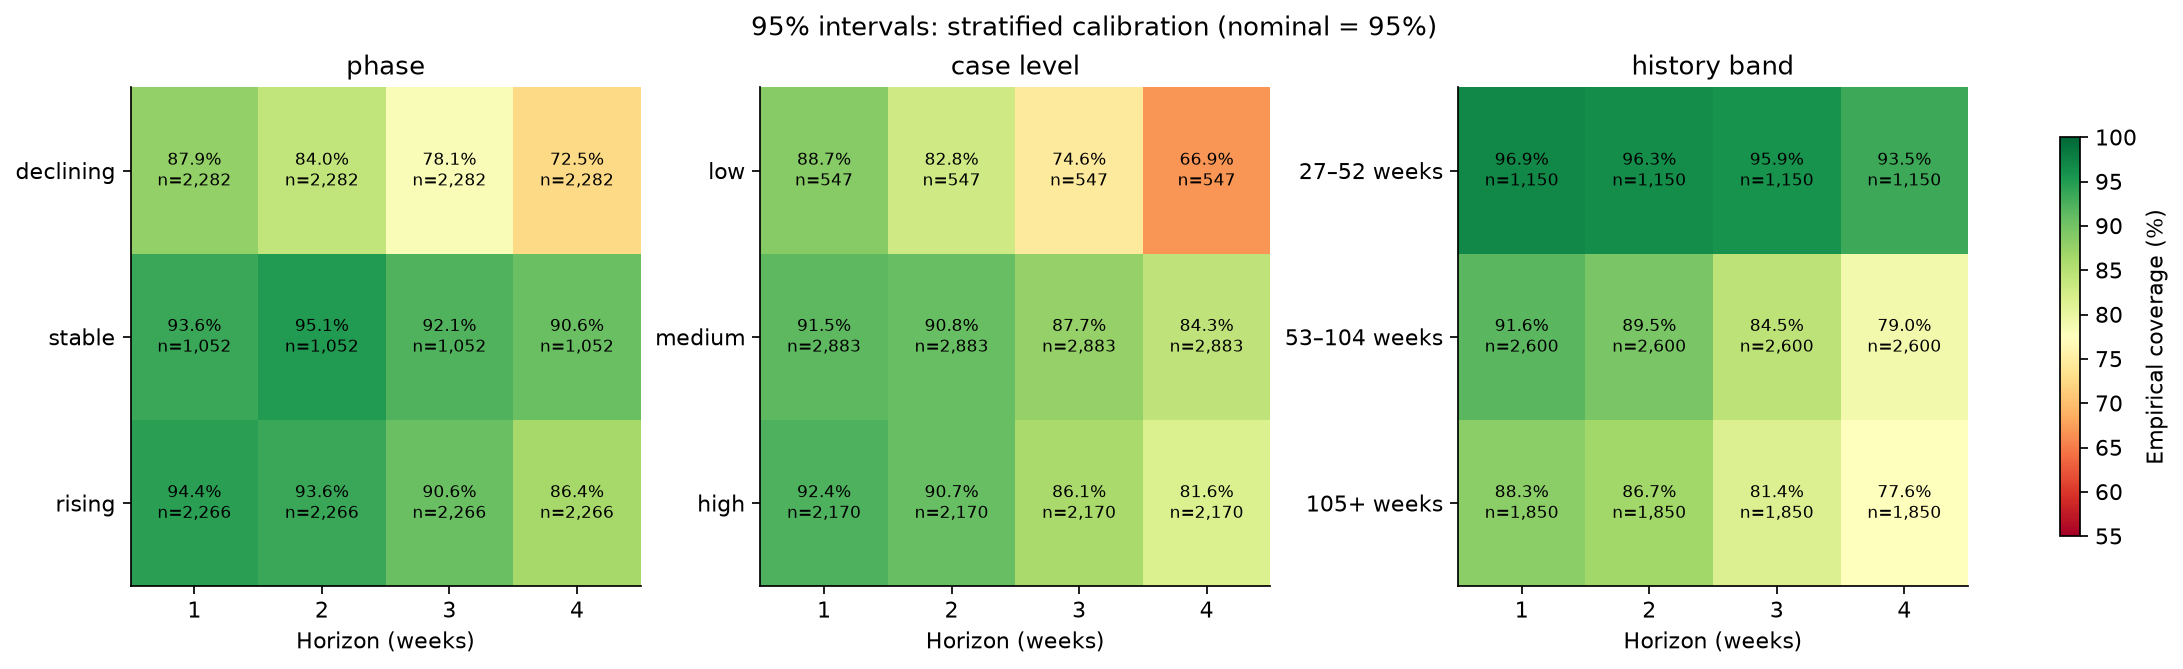

In [4]:
groups95 = calibration.loc[calibration.level.eq(.95) & calibration.dimension.isin(["phase", "case_level", "history_band"])]
display(groups95[["dimension", "group", "n", "states", "coverage", "coverage_lo", "coverage_hi", "calibration_gap", "MPIW", "normalized_MPIW"]])
display(Image(filename=str(OUT / "figures/stratified_coverage95.png")))


## Khoảng rộng có tương ứng với sai số lớn?

Raw width và error dễ cùng tăng theo scale. Xem thêm normalized và partial Spearman sau điều chỉnh origin context. Chỉ phân tích riêng từng horizon, không dùng bốn horizons làm bốn mẫu độc lập của cùng origin. Đây là quan hệ mô tả, chưa phải risk detector được xác nhận ngoài mẫu.

,horizon,analysis,n,rho,lo,hi
0,1,raw,5600,0.688316,0.646306,0.727277
1,1,normalized,5600,0.320288,0.291809,0.348192
2,1,context_adjusted,5600,0.097920,0.071789,0.129185
3,2,raw,5600,0.665209,0.621897,0.705488
4,2,normalized,5600,0.374810,0.345701,0.403880
5,2,context_adjusted,5600,0.115998,0.078828,0.150424
6,3,raw,5600,0.646478,0.607388,0.682449
7,3,normalized,5600,0.406192,0.383184,0.428587
8,3,context_adjusted,5600,0.131475,0.098957,0.161639
9,4,raw,5600,0.625623,0.584792,0.660384


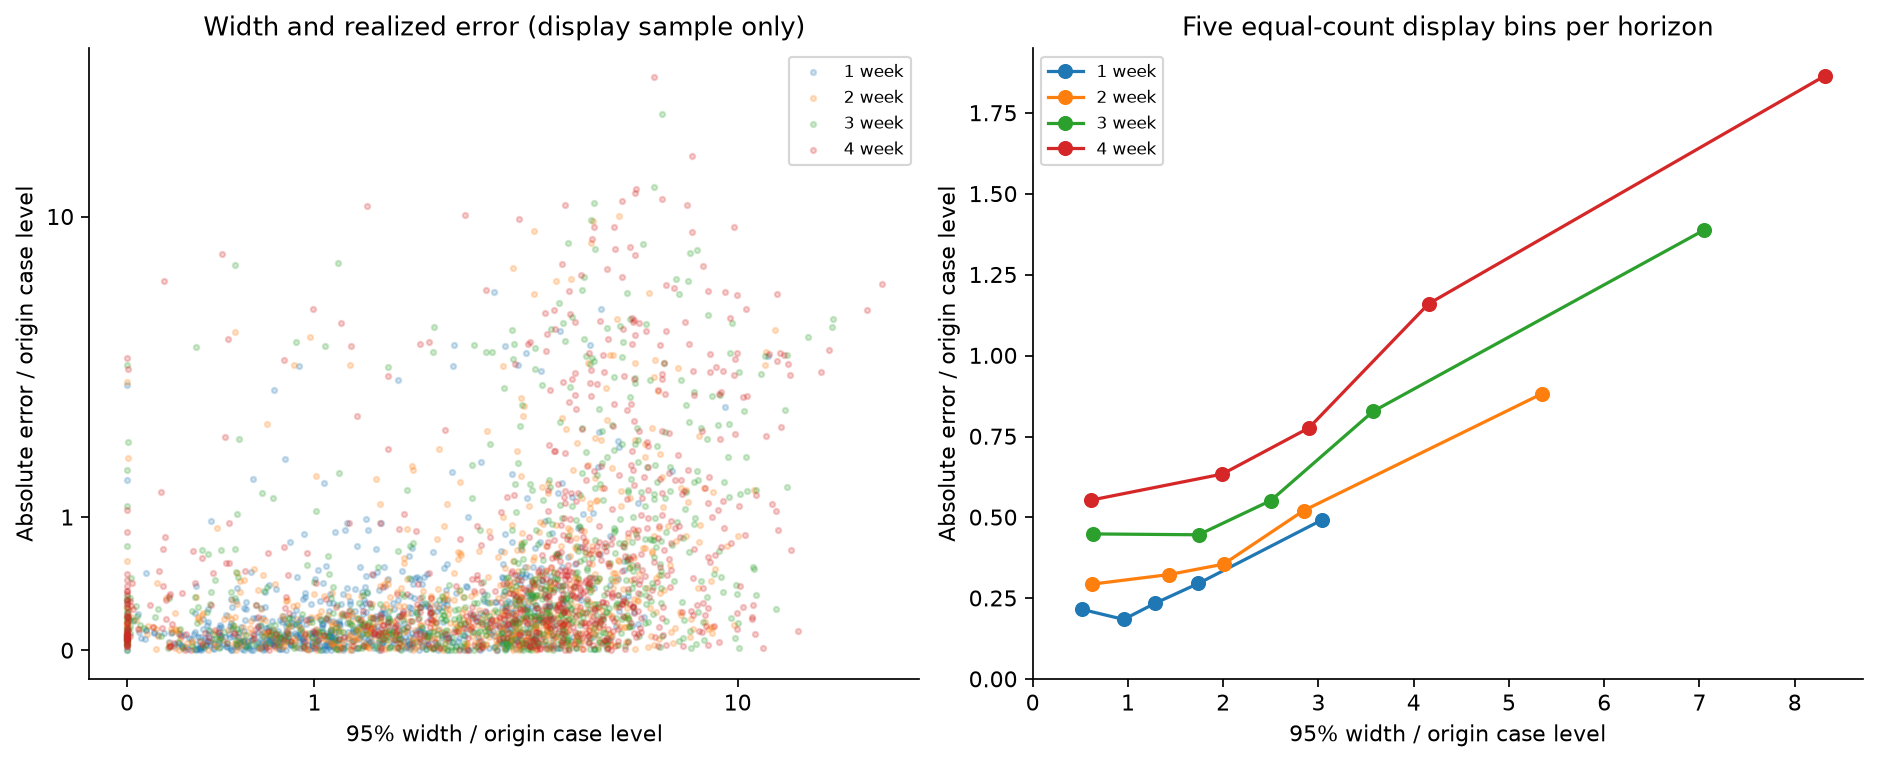

In [5]:
display(correlations)
display(Image(filename=str(OUT / "figures/width_error.png")))


## Dispersion và lượng calibration data

Tất cả forecasts đã dùng MLE từ origin đầu nhờ 24 warmup origins; **không có scored initial-size phase**. Số calibration pairs chỉ đếm targets đã đến hạn; nhóm `<24 pairs` có thể xuất hiện ở đầu horizons dài. Labels là final revisions và warmup dùng snapshot cố định, nên không đồng nghĩa toàn bộ dữ liệu đã có real-time. Width còn phụ thuộc point forecast và epidemic waves; không kết luận nhân quả rằng thêm pairs làm intervals tốt hơn.

,targets,size_median,min_pairs,max_pairs,future_label_fits
horizon,,,,,
1,5600,8.805723,24,135,0
2,5600,3.274726,23,134,0
3,5600,1.999694,22,133,0
4,5600,1.222433,21,132,0


,group,n,coverage,coverage_lo,coverage_hi,MPIW,normalized_MPIW
166,100+ pairs,6895,0.858303,0.826571,0.885216,28835.122810,2.484475
177,24–49 pairs,5200,0.950962,0.938553,0.962024,42705.539582,2.738903
188,50–99 pairs,10005,0.838881,0.824203,0.852039,45724.968701,2.751574
199,<24 pairs,300,0.936667,0.888250,0.973333,16691.313417,2.475793


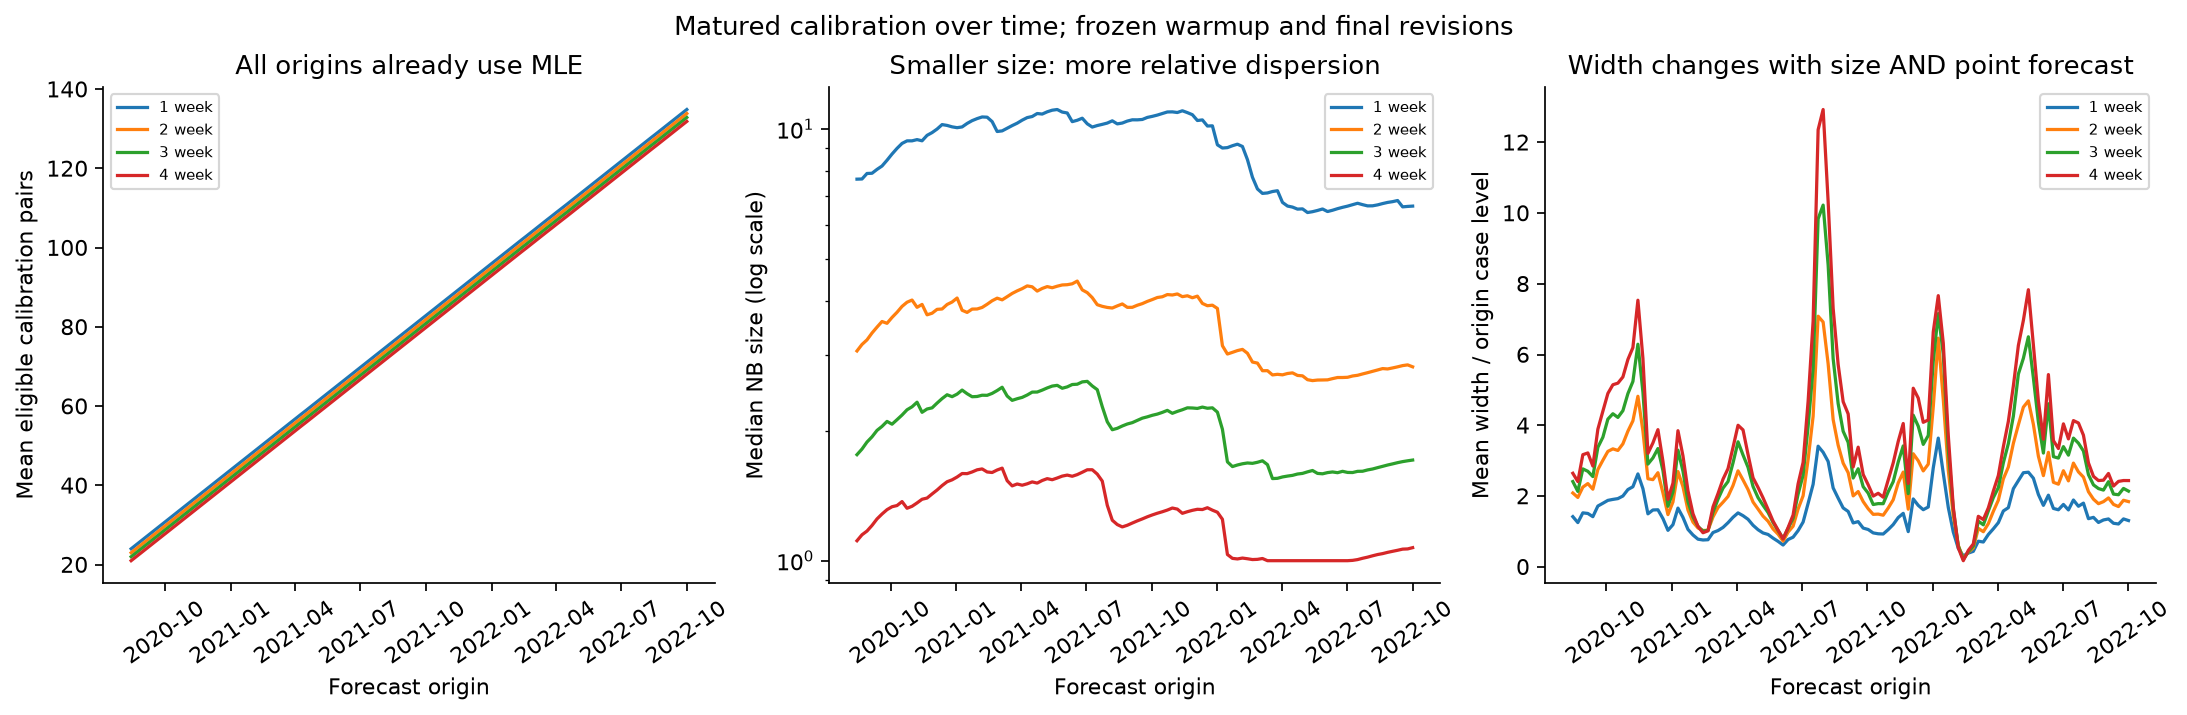

In [6]:
display(instances.groupby("horizon").agg(
    targets=("nb_size", "size"), size_median=("nb_size", "median"),
    min_pairs=("calibration_n", "min"), max_pairs=("calibration_n", "max"),
    future_label_fits=("future_calibration_n", lambda s: int(s.gt(0).sum()))))
display(calibration.loc[calibration.dimension.eq("calibration_band") & calibration.level.eq(.95),
    ["group", "n", "coverage", "coverage_lo", "coverage_hi", "MPIW", "normalized_MPIW"]])
display(Image(filename=str(OUT / "figures/dispersion_history.png")))


## Ví dụ forecast intervals

California, origin 18/12/2021 được cố định trước phân tích E6, chỉ dùng minh họa cách đọc median/50%/80%/95% intervals và truth; không đại diện cho accuracy toàn bộ cohort. Số liệu, nhận xét và giới hạn chi tiết nằm trong `outputs/experiment_6_nonconstant_v2_matured/report.md`.

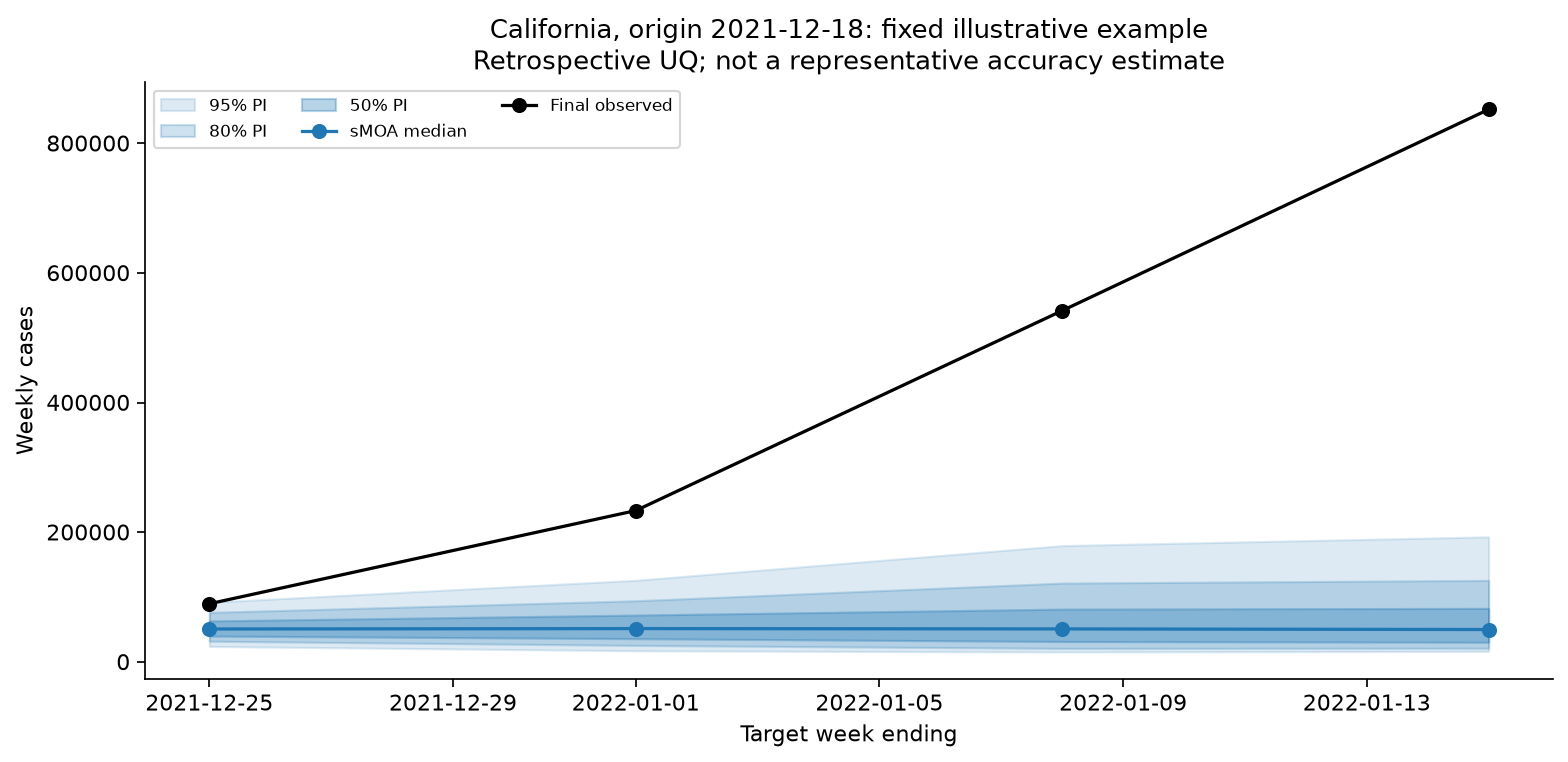



- Coverage 95% inclusive: **87.2188%**; nominal 95%, gap **-7.781 điểm phần trăm**; CI state-bootstrap [86.03%, 88.38%].
- MPIW 95%: **39,436.28 ca**; normalized MPIW **2.6627**.
- **WIS 4,747.38; MAE 7,384.66**. WIS dùng đúng bảy quantiles của pipeline, không đổi sang WIS 23 quantiles.
- Source coverage dùng L < y ≤ U: 87.1696%; inclusive thêm 11 targets ở biên dưới. Tất cả quantiles và WIS đã kiểm tra khớp output gốc.

| group | n | coverage | MPIW | normalized_MPIW | WIS | MAE |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | 5600 | 0.9159 | 23,848.2351 | 1.5060 | 2,628.4427 | 4,173.9304 |
| 2 | 5600 | 0.8996 | 38,115.7554 | 2.4501 | 4,008.5643 | 6,273.8829 |
| 3 | 5600 | 0.8580 | 45,993.7471 | 3.0996 | 5,655.2023 | 8,808.2905 |
| 4 | 5600 | 0.8152 | 49,787.3844 | 3.5952 | 6,697.3042 | 10,282.5428 |

**Khoảng 95% chưa đạt coverage 95%** trên cohort này: cả CI overall cũng nằm dưới nominal. Coverage giảm từ 91.59% ở tuần 1 xuống 81.52% ở tuần 4 dù MPIW tăng. Truth vượt upper bound trong 10.33% targets, thấp hơn lower bound trong 2.45%; phần miss chủ yếu nằm phía trên interval.



In [7]:
display(Image(filename=str(OUT / "figures/forecast_intervals.png")))
display(Markdown((OUT / "report.md").read_text().split("## Kết quả chính")[1].split("## Điều kiện dịch")[0].split("![Horizon")[0]))
